# Caviar results: which sequence models are worth tuning

**Short answer: tune `instr_gru`, a GRU with separate encoders for the two instruments.** It scored 0.6709 on masked validation, against 0.6171 for the supplied baseline, and it is the only top model measured under the speed limit. It passes by less than 1%, so it needs to be made faster before it is safe to submit.

## Findings

| Model | Masked validation | Real scorer speed | Limit is 91.4 µs per row |
|---|---|---|---|
| `group_gru` | 0.6716 | 94.9 and 95.7 µs | **Fails** |
| `instr_gru` | 0.6709 | 90.7 µs | Passes, projected 59.5 of 60 minutes |

Masked scores are the mean of 15 runs. Speeds are from one run of each model, on this machine.

1. **The training setup gave most of the gain.** A plain GRU shaped like the baseline scored 0.656 in Round 1, against the baseline's 0.617. That GRU uses clipped targets and a loss weighted by target size. Better designs added about 0.01 on top. We do not know how the baseline was trained, so this compares results and is not a controlled test.
2. **`group_gru` and `instr_gru` are effectively tied on score.** `group_gru` was higher in 13 of 15 paired runs, but by only 0.0007. Speed decides between them.
3. **The short speed test reads too low.** `group_gru` measured 78.8 µs in the test and about 95 µs in the real scorer. `instr_gru` went from 74.9 to 90.7 µs. Both gained about 16 µs, so read every speed in the tables below as about 16 µs too low. The other models were not run through the real scorer.
4. **Training was cut off by the 3,000-step cap.** All 45 Round 2 runs and 57 of 84 Round 1 neural runs reached it, so these scores show most models at a fixed budget, not at their best. Slower learners may be underrated.
5. **The two scores rank some models differently.** Round 2 was chosen by held-out fold score, as planned. That left out `gru2`, `lstm` and `cnn_lstm`, which placed 16th, 25th and 24th on folds but 6th, 10th and 11th on masked validation. Masked validation is closer to what the competition counts.

## What to do next

1. **Make `instr_gru` faster.** Shrink it until it runs well under the limit. The scorer's machine may be slower than this one, so 90.7 µs leaves no safe margin.
2. **Train it for longer than 3,000 steps** and on more sequences. Both are likely gains, because the runs hit the cap and Round 2's extra data lifted scores.
3. **Run `gru2` through Round 2.** It is the most likely model to have been wrongly screened out, and it is simpler than `instr_gru`.

## Limits of these results

- **Speed:** measured on this machine only. Nothing here has been run on the real scorer's hardware.
- **`instr_gru` check:** one pass, so repeat predictions and speed were not tested on it. `group_gru` ran twice, with identical predictions.
- **Baseline fold score:** the baseline scores about 0.40 on Round 1 folds, but it may have been trained on those sequences, so compare it on masked validation only.
- **`ema_gbm`:** trained on 400 sequences, not 1,500, so it is not a fair comparison.
- **`mgu`:** paused at step 750 of 3,000 on all 3 folds, so it has no score yet. To resume: `python -m caviar.run_all --round r1 --parallel 3 --keys mgu --gpu-fraction 0.3`.


In [1]:
import glob, json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / 'reports').exists() else Path.cwd().parent
REPORTS = ROOT / 'reports'
LIMIT_US = 91.4
RISKY_US = 60
UNDER, OVER, INK, MUTED = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'

results = pd.read_csv(REPORTS / 'caviar_results.csv')
speed = pd.read_csv(REPORTS / 'caviar_speed.csv').set_index('key')
baseline = json.loads((REPORTS / 'caviar_baseline.json').read_text())
BASE_MASKED = baseline['valid_masked']['wp']
BASE_ALL = baseline['valid_all']['wp']
BASE_CV = sum(f['wp'] for f in baseline['r1_folds'].values()) / len(baseline['r1_folds'])

NOTES = {'ema_gbm': 'trained on 400 sequences, not 1,500; no speed number',
         'plstm': 'cannot export to ONNX',
         'constant': 'sanity check', 'ridge': 'current row only'}

def summarize(frame):
    table = frame.groupby('key').agg(
        runs=('cv_wp', 'size'), cv=('cv_wp', 'mean'), cv_spread=('cv_wp', 'std'),
        masked=('valid_masked_wp', 'mean'), all_rows=('valid_all_wp', 'mean'),
        t0=('valid_masked_t0', 'mean'), t1=('valid_masked_t1', 'mean'), params=('params', 'first'))
    table['us_per_row'] = speed['us_per_row'].reindex(table.index)
    return table.sort_values('cv', ascending=False)

def speed_label(us):
    if pd.isna(us):
        return 'not timed'
    return 'over' if us > LIMIT_US else 'risky' if us > RISKY_US else 'ok'

def show(table):
    return table.style.format({'cv': '{:.4f}', 'cv_spread': '{:.4f}', 'masked': '{:.4f}', 'all_rows': '{:.4f}',
                               't0': '{:.4f}', 't1': '{:.4f}', 'params': '{:,.0f}', 'us_per_row': '{:.1f}'}, na_rep='')

## Round 1: every model

Mean of 3 folds on 1,500 sequences, sorted by held-out fold score (`cv`). `masked` is the score on the
validation rows the competition counts, comparable to the published 0.617052. `all_rows` is the
same file with every row counted. `us_per_row` and `speed` come from the short speed test, which reads about 16 µs too
low: `group_gru` shows as `risky` here but failed in the real scorer. `risky` means 60 to 91.4 µs per row, and `over` means
above the 91.4 µs limit.

In [2]:
round1 = summarize(results[results['round'] == 'r1'])
round1['speed'] = round1['us_per_row'].map(speed_label)
round1['note'] = [NOTES.get(key, '') for key in round1.index]
missing = [key for key in speed.index if key not in round1.index]
print('Baseline: masked', round(BASE_MASKED, 4), ' all rows', round(BASE_ALL, 4), ' CV folds', round(BASE_CV, 4))
print('Not finished:', missing or 'none')
show(round1)

Baseline: masked 0.6171  all rows 0.4402  CV folds 0.4034
Not finished: ['mgu']


,runs,cv,cv_spread,masked,all_rows,t0,t1,params,us_per_row,speed,note
key,,,,,,,,,,,
instr_gru,3,0.4094,0.0144,0.6664,0.4860,0.6607,0.6721,"118,050",74.9,risky,
group_gru,3,0.4088,0.0237,0.6681,0.4888,0.6630,0.6733,"120,642",78.8,risky,
sru,3,0.4018,0.0146,0.6573,0.4740,0.6523,0.6624,"163,330",102.9,over,
twospeed,3,0.3928,0.0151,0.6582,0.4767,0.6521,0.6644,"130,562",80.6,risky,
ema_gbm,3,0.3898,0.0084,0.6354,0.4655,0.6296,0.6411,461,,not timed,"trained on 400 sequences, not 1,500; no speed number"
gru_attn,3,0.3898,0.0151,0.6581,0.4724,0.6523,0.6639,"159,618",99.3,over,
resgru,3,0.3889,0.0115,0.6489,0.4583,0.6426,0.6553,"213,378",83.9,risky,
qrnn,3,0.3878,0.0140,0.6503,0.4636,0.6438,0.6569,"185,346",104.2,over,
rwkv,3,0.3856,0.0179,0.6496,0.4645,0.6450,0.6542,"160,802",118.1,over,


## Round 2: the top 5 under the speed limit

5 folds on 5,000 sequences. `group_gru` and `instr_gru` have 3 seeds each, so 15 runs.

In [3]:
round2_runs = results[results['round'] == 'r2']
round2 = summarize(round2_runs)
round2['speed'] = round2['us_per_row'].map(speed_label)
show(round2)

,runs,cv,cv_spread,masked,all_rows,t0,t1,params,us_per_row,speed
key,,,,,,,,,,
group_gru,15,0.4335,0.0039,0.6716,0.4958,0.6663,0.6768,"120,642",78.8,risky
instr_gru,15,0.4318,0.0038,0.6709,0.4946,0.6656,0.6762,"118,050",74.9,risky
resgru,5,0.4279,0.0041,0.6677,0.4934,0.6622,0.6733,"213,378",83.9,risky
twospeed,5,0.4269,0.0038,0.6680,0.4924,0.6625,0.6735,"130,562",80.6,risky
rnn,5,0.4018,0.0061,0.6542,0.4720,0.6488,0.6597,"226,818",65.7,risky


## Is the `group_gru` lead real?

Each pair below shares a seed and fold, so the comparison removes most of the fold-to-fold spread.

In [4]:
top_two = round2_runs[round2_runs['key'].isin(['group_gru', 'instr_gru'])]
print(top_two.groupby(['key', 'seed'])[['cv_wp', 'valid_masked_wp', 'valid_all_wp']].mean().round(4), '\n')
for column in ['cv_wp', 'valid_masked_wp', 'valid_all_wp']:
    pairs = top_two.pivot_table(index=['seed', 'fold'], columns='key', values=column)
    gap = pairs['group_gru'] - pairs['instr_gru']
    print(f'{column}: group_gru minus instr_gru = {gap.mean():+.5f}, '
          f'group_gru higher in {(gap > 0).sum()} of {len(gap)} paired runs')

                 cv_wp  valid_masked_wp  valid_all_wp
key       seed                                       
group_gru 0     0.4331           0.6716        0.4957
          1     0.4337           0.6716        0.4956
          2     0.4339           0.6714        0.4961
instr_gru 0     0.4311           0.6707        0.4943
          1     0.4322           0.6711        0.4950
          2     0.4320           0.6709        0.4946 

cv_wp: group_gru minus instr_gru = +0.00180, group_gru higher in 14 of 15 paired runs
valid_masked_wp: group_gru minus instr_gru = +0.00067, group_gru higher in 13 of 15 paired runs
valid_all_wp: group_gru minus instr_gru = +0.00118, group_gru higher in 12 of 15 paired runs


## Where the two scores disagree, and what speed costs

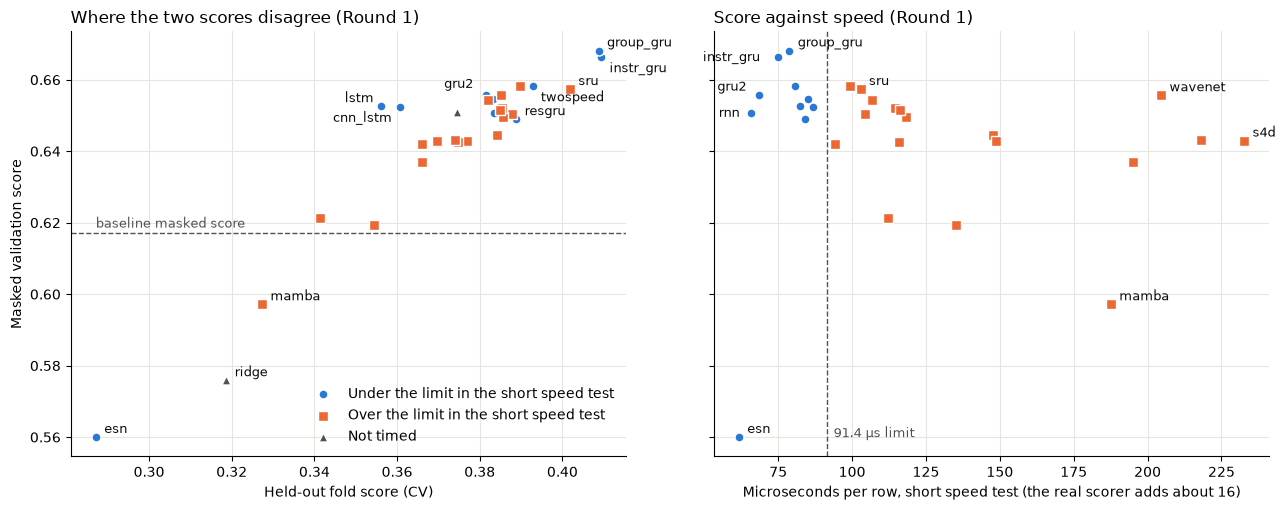

Rank correlation between the two scores: 0.77
          cv  masked  moved
key                        
lstm      25      10     15
cnn_lstm  24      11     13
gru2      16       6     10
tcn_gru   15       9      6
cnn_gru   14       8      6
plstm     19      14      5


In [5]:
def labelled_scatter(ax, frame, x, y, labels, offsets=None):
    offsets = offsets or {}
    for name, color, marker, part in [
            ('Under the limit in the short speed test', UNDER, 'o', frame[frame['us_per_row'] <= LIMIT_US]),
            ('Over the limit in the short speed test', OVER, 's', frame[frame['us_per_row'] > LIMIT_US]),
            ('Not timed', MUTED, '^', frame[frame['us_per_row'].isna()])]:
        if part.empty:
            continue
        ax.scatter(part[x], part[y], s=42, c=color, marker=marker, edgecolors='white', linewidths=1, label=name, zorder=3)
    for key in labels:
        if key in frame.index:
            ax.annotate(key, (frame.loc[key, x], frame.loc[key, y]), xytext=offsets.get(key, (6, 3)),
                        textcoords='offset points', fontsize=9, color=INK)
    ax.grid(color='#e6e5e0', linewidth=0.8, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)

plotted = round1.drop(index=[k for k in ['constant', 'ema_gbm'] if k in round1.index])
figure, (left, right) = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)

labelled_scatter(left, plotted, 'cv', 'masked',
                 ['group_gru', 'instr_gru', 'sru', 'twospeed', 'gru2', 'lstm', 'cnn_lstm', 'resgru', 'mamba', 'ridge', 'esn'],
                 {'gru2': (-30, 5), 'instr_gru': (6, -11), 'lstm': (-26, 3), 'cnn_lstm': (-48, -11), 'twospeed': (6, -11)})
left.axhline(BASE_MASKED, color=MUTED, linewidth=1, linestyle='--')
left.annotate('baseline masked score', (plotted['cv'].min(), BASE_MASKED), xytext=(0, 4), textcoords='offset points', fontsize=9, color=MUTED)
left.set_xlabel('Held-out fold score (CV)')
left.set_ylabel('Masked validation score')
left.set_title('Where the two scores disagree (Round 1)', loc='left', fontsize=12)

timed = plotted.dropna(subset=['us_per_row'])
labelled_scatter(right, timed, 'us_per_row', 'masked',
                 ['group_gru', 'instr_gru', 'sru', 'rnn', 'wavenet', 's4d', 'gru2', 'esn', 'mamba'],
                 {'instr_gru': (-54, -3), 'gru2': (-30, 3), 'rnn': (-23, -3)})
right.axvline(LIMIT_US, color=MUTED, linewidth=1, linestyle='--')
right.annotate('91.4 µs limit', (LIMIT_US, plotted['masked'].min()), xytext=(5, 0), textcoords='offset points', fontsize=9, color=MUTED)
right.set_xlabel('Microseconds per row, short speed test (the real scorer adds about 16)')
right.set_title('Score against speed (Round 1)', loc='left', fontsize=12)
left.legend(frameon=False, loc='lower right')
figure.tight_layout()
plt.show()

rank = plotted[['cv', 'masked']].rank(ascending=False).astype(int)
rank['moved'] = rank['cv'] - rank['masked']
print('Rank correlation between the two scores:', round(plotted['cv'].corr(plotted['masked'], method='spearman'), 2))
print(rank.sort_values('moved', ascending=False).head(6).to_string())

## How many runs reached the step cap?

Early stopping almost never fired, so these scores show each model at 3,000 steps, not at its best.

In [6]:
trained = results[results['stopped_step'] > 0]
budget = trained[trained['key'] != 'ema_gbm'].groupby('round').agg(
    runs=('stopped_step', 'size'), reached_cap=('stopped_step', lambda s: int((s == 3000).sum())),
    mean_best_step=('best_step', 'mean'))
budget

,runs,reached_cap,mean_best_step
round,,,
r1,84,57,1898.809524
r2,45,45,2600.000000


## Scorer check

The model, exported to ONNX and run through the real `ScorerStepByStep` on all of validation, on one thread.

In [7]:
for path in sorted(glob.glob(str(REPORTS / 'caviar_verify_*.json'))):
    check = json.loads(Path(path).read_text())
    print(Path(path).name)
    for index, single in enumerate(check['passes']):
        print(f"  pass {index}: score {single['score']:.6f}, {single['us_per_row']:.1f} µs per row, {single['seconds'] / 60:.1f} min")
    print(f"  score from training {check['score_from_training']:.6f}, gap {check['score_gap']:.2e}")
    repeat = check['same_predictions'] if len(check['passes']) > 1 else 'not tested, one pass'
    print(f"  same predictions: {repeat}, score matches: {check['score_matches']}, under limit: {check['under_limit']}")

caviar_verify_group_gru_s0_f0.json
  pass 0: score 0.673420, 94.9 µs per row, 59.3 min
  pass 1: score 0.673420, 95.7 µs per row, 59.8 min
  score from training 0.673421, gap 2.52e-07
  same predictions: True, score matches: True, under limit: False
caviar_verify_instr_gru_s0_f0.json
  pass 0: score 0.671374, 90.7 µs per row, 56.6 min
  score from training 0.671374, gap 6.44e-08
  same predictions: not tested, one pass, score matches: True, under limit: True
